# 03 · Перплексія + стилометрія + SHAP (GPU T4, Internet On)
**Вхід:** змагання + вихід ноутбука 00 (`split_32k.csv`). **Вихід:** `ppl_*.npy`, `gbm_val.npy`, `gbm_test.npy`. Час ~30-40 хв.

Експеримент: чи можна відрізнити human / ai / fusion за ознаками "передбачуваності" тексту (маленька відкрита мовна модель Qwen2.5-0.5B) і простою стилометрією, без нейромережі-класифікатора. Далі LightGBM на цих 20 ознаках, абляція (які ознаки потрібні) і SHAP.

**Референси на тому самому спліті** (train ~32k, val 8 005): TF-IDF 0.8598 (ноутбук 01), XLM-R 0.904 (ноутбук 02).

## Шапка: дані та спліт
Читає дані змагання та `split_32k.csv` з ноутбука 00. Спліт груповий: людський текст і його AI/fusion версії завжди в одній частині, тож валідація (8 005 текстів) чесно імітує тест.

In [1]:
import os, glob, warnings, numpy as np, pandas as pd
warnings.filterwarnings("ignore")
from sklearn.metrics import f1_score, classification_report, confusion_matrix

ID, TEXT, LABEL = "id", "text", "label"
SEED = 42
LABELS = ["human", "ai", "fusion"]
OUT = "/kaggle/working"

def find(name):
    return glob.glob(f"/kaggle/input/**/{name}", recursive=True)[0]

train = pd.read_csv(find("train.csv"))
test = pd.read_csv(find("test.csv"))
ss = pd.read_csv(find("sample_submission.csv"))

# спліт береться з ноутбука 0 (split.csv): вся група "людський текст + його AI/fusion версії" лежить в одній частині
SPLIT_FILE = "split_32k.csv"   # train ~32k, той самий, що в ноутбуці 01
sp = pd.read_csv(find(SPLIT_FILE))
d = train.merge(sp, on=ID)
tr = d[d.part == "tr"].reset_index(drop=True)
va = d[d.part == "va"].reset_index(drop=True)
l2i = {l: i for i, l in enumerate(LABELS)}
ytr, yva = tr[LABEL].map(l2i).values, va[LABEL].map(l2i).values
print(train.columns.tolist(), "| train:", len(tr), "val:", len(va), "test:", len(test))

def save_sub(p, fn):  # p = матриця ймовірностей для test, пише файл у форматі Kaggle
    out = pd.DataFrame({ID: test[ID], LABEL: np.array(LABELS)[p.argmax(1)]})
    out.set_index(ID).loc[ss[ID]].reset_index().to_csv(f"{OUT}/{fn}", index=False)

['id', 'text', 'lang', 'domain', 'label'] | train: 31995 val: 8005 test: 25000


## Перплексійні ознаки
Маленька відкрита мовна модель (Qwen 0.5B) показує, наскільки вона "здивована" текстом. AI-текст зазвичай передбачуваніший (вища середня логймовірність, нижча ентропія). Для fusion додано ознаки по 4 шматках тексту: якщо початок і кінець різні за передбачуваністю (`lp_chunk_std`, `lp_chunk_diff`), це схоже на змішаний текст.

In [2]:
import torch, re
from transformers import AutoTokenizer, AutoModelForCausalLM

LM = "Qwen/Qwen2.5-0.5B"
dev = "cuda"
ltok = AutoTokenizer.from_pretrained(LM); ltok.padding_side = "right"
if ltok.pad_token is None: ltok.pad_token = ltok.eos_token
lm = AutoModelForCausalLM.from_pretrained(LM, torch_dtype=torch.float16).to(dev).eval()

@torch.no_grad()
def ppl_feats(texts, bs=8, max_len=256):
    order = np.argsort([len(t) for t in texts])
    out = np.zeros((len(texts), 10), dtype=np.float32)
    for s in range(0, len(texts), bs):
        idx = order[s:s + bs]
        enc = ltok([texts[j][:3000] for j in idx], return_tensors="pt", truncation=True,
                   max_length=max_len, padding=True).to(dev)
        lg = lm(**enc).logits[:, :-1].float()
        lp = torch.log_softmax(lg, -1)
        tlp = lp.gather(-1, enc.input_ids[:, 1:, None])[..., 0]    # логймовірність справжнього токена
        ent = -(lp.exp() * lp).sum(-1)                              # ентропія передбачення
        msk = enc.attention_mask[:, 1:].bool()
        for b, j in enumerate(idx):
            x, e = tlp[b][msk[b]].cpu().numpy(), ent[b][msk[b]].cpu().numpy()
            if len(x) < 4:
                out[j] = np.nan; continue
            ch = [c.mean() for c in np.array_split(x, 4)]           # середнє по 4 шматках
            out[j] = [x.mean(), x.std(), x.min(), e.mean(), e.std(), x.mean() + e.mean(),
                      ch[0], ch[3], np.std(ch), ch[3] - ch[0]]
    return out

F_tr, F_va, F_te = [ppl_feats(d[TEXT].tolist()) for d in (tr, va, test)]
np.save(f"{OUT}/ppl_tr.npy", F_tr); np.save(f"{OUT}/ppl_va.npy", F_va); np.save(f"{OUT}/ppl_te.npy", F_te)
print(F_tr.shape)

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

(31995, 10)


## Стилометрія
Прості стильові ознаки: довжина, середня довжина слова, частка розділових знаків, довжина речень, різноманітність лексики (TTR) тощо.

In [3]:
def style(t):
    t = t[:20000]
    w = t.split()
    sl = [len(x.split()) for x in re.split(r"[.!?]+\s", t) if x.strip()] or [0]
    n = max(len(t), 1)
    return [len(t), len(w), np.mean([len(x) for x in w]) if w else 0,
            sum(c in ".,;:!?" for c in t) / n, sum(c.isupper() for c in t) / n,
            sum(c.isdigit() for c in t) / n, np.mean(sl), np.std(sl),
            len(set(x.lower() for x in w)) / max(len(w), 1), t.count("\n") / n]

S_tr, S_va, S_te = [np.array([style(t) for t in d[TEXT]], dtype=np.float32) for d in (tr, va, test)]
names = ["lp_mean", "lp_std", "lp_min", "ent_mean", "ent_std", "lp+ent", "lp_chunk1", "lp_chunk4",
         "lp_chunk_std", "lp_chunk_diff",
         "n_chars", "n_words", "avg_word_len", "punct", "upper", "digits", "sent_mean", "sent_std", "ttr", "newlines"]

## Бустинг на ознаках
LightGBM на 20 числових ознаках (10 перплексійних + 10 стилометричних), `class_weight="balanced"`. Метрики по класах на валідації.

In [4]:
import lightgbm as lgb
Ftr, Fva, Fte = np.hstack([F_tr, S_tr]), np.hstack([F_va, S_va]), np.hstack([F_te, S_te])

gbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                         class_weight="balanced", random_state=SEED, verbose=-1)
gbm.fit(Ftr, ytr)
pva = gbm.predict_proba(Fva)
print("macro-F1:", round(f1_score(yva, pva.argmax(1), average="macro"), 4))
print(classification_report(yva, pva.argmax(1), target_names=LABELS, digits=3))
np.save(f"{OUT}/gbm_val.npy", pva); np.save(f"{OUT}/gbm_test.npy", gbm.predict_proba(Fte))

macro-F1: 0.7431
              precision    recall  f1-score   support

       human      0.598     0.745     0.663      1950
          ai      0.940     0.942     0.941      3556
      fusion      0.700     0.563     0.624      2499

    accuracy                          0.776      8005
   macro avg      0.746     0.750     0.743      8005
weighted avg      0.782     0.776     0.775      8005



## Абляція: які ознаки потрібні
Той самий GBM, той самий спліт, але різні набори ознак.

In [5]:
rows = []
sets = {"тільки перплексія (10)": (F_tr, F_va), "тільки стилометрія (10)": (S_tr, S_va), "перплексія + стилометрія (20)": (Ftr, Fva)}
for nm, (a, b) in sets.items():
    g = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                           class_weight="balanced", random_state=SEED, verbose=-1).fit(a, ytr)
    rows.append((nm, round(f1_score(yva, g.predict(b), average="macro"), 4)))
print(pd.DataFrame(rows, columns=["ознаки", "macro-F1"]))

                          ознаки  macro-F1
0         тільки перплексія (10)    0.5403
1        тільки стилометрія (10)    0.7007
2  перплексія + стилометрія (20)    0.7431


## SHAP (xAI)
Вплив ознак на рішення GBM (середня абсолютна SHAP-цінність за класами).

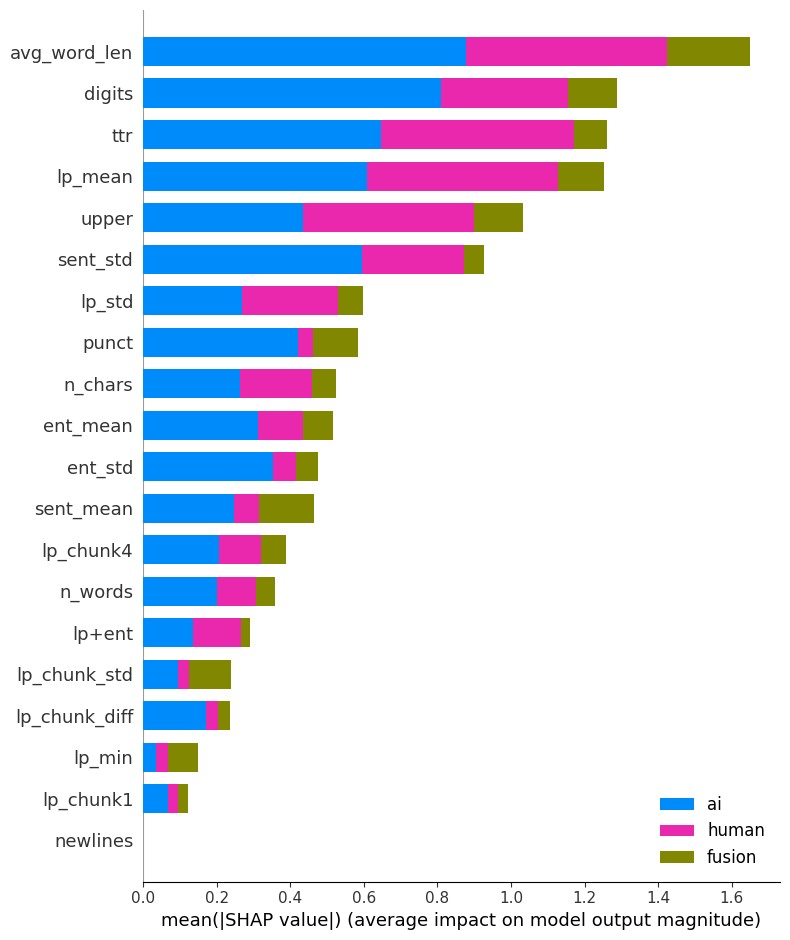

In [6]:
import shap, matplotlib.pyplot as plt
sv = shap.TreeExplainer(gbm).shap_values(Fva[:2000])
shap.summary_plot(sv, Fva[:2000], feature_names=names, plot_type="bar", class_names=LABELS)